# CryptoHack: Symmetric Ciphers

Solutions to the **Symmetric Ciphers** course on [CryptoHack](https://cryptohack.org/courses/symmetric/course_details/).
The first part re-implements AES-128 decryption from scratch; the second part attacks misuses of
block cipher modes through the challenges' HTTP APIs.

# How AES Works

## Structure of AES

AES operates on a 16-byte block arranged as a 4x4 matrix of bytes, called the *state*.

In [1]:
def bytes2matrix(text):
    """Convert a 16-byte array into a 4x4 matrix."""
    return [list(text[i:i + 4]) for i in range(0, len(text), 4)]


def matrix2bytes(matrix):
    """Convert a 4x4 matrix into a 16-byte array."""
    return bytes(b for row in matrix for b in row)


matrix = [
    [99, 114, 121, 112],
    [116, 111, 123, 105],
    [110, 109, 97, 116],
    [114, 105, 120, 125],
]

print(matrix2bytes(matrix).decode())

crypto{inmatrix}


## Round Keys

`AddRoundKey` XORs the state with the current round key, byte by byte.

In [2]:
def add_round_key(state, key):
    return [[s ^ k for s, k in zip(state_row, key_row)] for state_row, key_row in zip(state, key)]


state = [
    [206, 243, 61, 34],
    [171, 11, 93, 31],
    [16, 200, 91, 108],
    [150, 3, 194, 51],
]

round_key = [
    [173, 129, 68, 82],
    [223, 100, 38, 109],
    [32, 189, 53, 8],
    [253, 48, 187, 78],
]

print(matrix2bytes(add_round_key(state, round_key)).decode())

crypto{r0undk3y}


## Confusion through Substitution

`SubBytes` replaces each byte with its image through the S-box, a highly non-linear lookup table.
Decryption uses the inverse S-box.

In [3]:
s_box = (
    0x63, 0x7C, 0x77, 0x7B, 0xF2, 0x6B, 0x6F, 0xC5, 0x30, 0x01, 0x67, 0x2B, 0xFE, 0xD7, 0xAB, 0x76,
    0xCA, 0x82, 0xC9, 0x7D, 0xFA, 0x59, 0x47, 0xF0, 0xAD, 0xD4, 0xA2, 0xAF, 0x9C, 0xA4, 0x72, 0xC0,
    0xB7, 0xFD, 0x93, 0x26, 0x36, 0x3F, 0xF7, 0xCC, 0x34, 0xA5, 0xE5, 0xF1, 0x71, 0xD8, 0x31, 0x15,
    0x04, 0xC7, 0x23, 0xC3, 0x18, 0x96, 0x05, 0x9A, 0x07, 0x12, 0x80, 0xE2, 0xEB, 0x27, 0xB2, 0x75,
    0x09, 0x83, 0x2C, 0x1A, 0x1B, 0x6E, 0x5A, 0xA0, 0x52, 0x3B, 0xD6, 0xB3, 0x29, 0xE3, 0x2F, 0x84,
    0x53, 0xD1, 0x00, 0xED, 0x20, 0xFC, 0xB1, 0x5B, 0x6A, 0xCB, 0xBE, 0x39, 0x4A, 0x4C, 0x58, 0xCF,
    0xD0, 0xEF, 0xAA, 0xFB, 0x43, 0x4D, 0x33, 0x85, 0x45, 0xF9, 0x02, 0x7F, 0x50, 0x3C, 0x9F, 0xA8,
    0x51, 0xA3, 0x40, 0x8F, 0x92, 0x9D, 0x38, 0xF5, 0xBC, 0xB6, 0xDA, 0x21, 0x10, 0xFF, 0xF3, 0xD2,
    0xCD, 0x0C, 0x13, 0xEC, 0x5F, 0x97, 0x44, 0x17, 0xC4, 0xA7, 0x7E, 0x3D, 0x64, 0x5D, 0x19, 0x73,
    0x60, 0x81, 0x4F, 0xDC, 0x22, 0x2A, 0x90, 0x88, 0x46, 0xEE, 0xB8, 0x14, 0xDE, 0x5E, 0x0B, 0xDB,
    0xE0, 0x32, 0x3A, 0x0A, 0x49, 0x06, 0x24, 0x5C, 0xC2, 0xD3, 0xAC, 0x62, 0x91, 0x95, 0xE4, 0x79,
    0xE7, 0xC8, 0x37, 0x6D, 0x8D, 0xD5, 0x4E, 0xA9, 0x6C, 0x56, 0xF4, 0xEA, 0x65, 0x7A, 0xAE, 0x08,
    0xBA, 0x78, 0x25, 0x2E, 0x1C, 0xA6, 0xB4, 0xC6, 0xE8, 0xDD, 0x74, 0x1F, 0x4B, 0xBD, 0x8B, 0x8A,
    0x70, 0x3E, 0xB5, 0x66, 0x48, 0x03, 0xF6, 0x0E, 0x61, 0x35, 0x57, 0xB9, 0x86, 0xC1, 0x1D, 0x9E,
    0xE1, 0xF8, 0x98, 0x11, 0x69, 0xD9, 0x8E, 0x94, 0x9B, 0x1E, 0x87, 0xE9, 0xCE, 0x55, 0x28, 0xDF,
    0x8C, 0xA1, 0x89, 0x0D, 0xBF, 0xE6, 0x42, 0x68, 0x41, 0x99, 0x2D, 0x0F, 0xB0, 0x54, 0xBB, 0x16,
)

inv_s_box = (
    0x52, 0x09, 0x6A, 0xD5, 0x30, 0x36, 0xA5, 0x38, 0xBF, 0x40, 0xA3, 0x9E, 0x81, 0xF3, 0xD7, 0xFB,
    0x7C, 0xE3, 0x39, 0x82, 0x9B, 0x2F, 0xFF, 0x87, 0x34, 0x8E, 0x43, 0x44, 0xC4, 0xDE, 0xE9, 0xCB,
    0x54, 0x7B, 0x94, 0x32, 0xA6, 0xC2, 0x23, 0x3D, 0xEE, 0x4C, 0x95, 0x0B, 0x42, 0xFA, 0xC3, 0x4E,
    0x08, 0x2E, 0xA1, 0x66, 0x28, 0xD9, 0x24, 0xB2, 0x76, 0x5B, 0xA2, 0x49, 0x6D, 0x8B, 0xD1, 0x25,
    0x72, 0xF8, 0xF6, 0x64, 0x86, 0x68, 0x98, 0x16, 0xD4, 0xA4, 0x5C, 0xCC, 0x5D, 0x65, 0xB6, 0x92,
    0x6C, 0x70, 0x48, 0x50, 0xFD, 0xED, 0xB9, 0xDA, 0x5E, 0x15, 0x46, 0x57, 0xA7, 0x8D, 0x9D, 0x84,
    0x90, 0xD8, 0xAB, 0x00, 0x8C, 0xBC, 0xD3, 0x0A, 0xF7, 0xE4, 0x58, 0x05, 0xB8, 0xB3, 0x45, 0x06,
    0xD0, 0x2C, 0x1E, 0x8F, 0xCA, 0x3F, 0x0F, 0x02, 0xC1, 0xAF, 0xBD, 0x03, 0x01, 0x13, 0x8A, 0x6B,
    0x3A, 0x91, 0x11, 0x41, 0x4F, 0x67, 0xDC, 0xEA, 0x97, 0xF2, 0xCF, 0xCE, 0xF0, 0xB4, 0xE6, 0x73,
    0x96, 0xAC, 0x74, 0x22, 0xE7, 0xAD, 0x35, 0x85, 0xE2, 0xF9, 0x37, 0xE8, 0x1C, 0x75, 0xDF, 0x6E,
    0x47, 0xF1, 0x1A, 0x71, 0x1D, 0x29, 0xC5, 0x89, 0x6F, 0xB7, 0x62, 0x0E, 0xAA, 0x18, 0xBE, 0x1B,
    0xFC, 0x56, 0x3E, 0x4B, 0xC6, 0xD2, 0x79, 0x20, 0x9A, 0xDB, 0xC0, 0xFE, 0x78, 0xCD, 0x5A, 0xF4,
    0x1F, 0xDD, 0xA8, 0x33, 0x88, 0x07, 0xC7, 0x31, 0xB1, 0x12, 0x10, 0x59, 0x27, 0x80, 0xEC, 0x5F,
    0x60, 0x51, 0x7F, 0xA9, 0x19, 0xB5, 0x4A, 0x0D, 0x2D, 0xE5, 0x7A, 0x9F, 0x93, 0xC9, 0x9C, 0xEF,
    0xA0, 0xE0, 0x3B, 0x4D, 0xAE, 0x2A, 0xF5, 0xB0, 0xC8, 0xEB, 0xBB, 0x3C, 0x83, 0x53, 0x99, 0x61,
    0x17, 0x2B, 0x04, 0x7E, 0xBA, 0x77, 0xD6, 0x26, 0xE1, 0x69, 0x14, 0x63, 0x55, 0x21, 0x0C, 0x7D,
)


def sub_bytes(state, sbox=s_box):
    return [[sbox[b] for b in row] for row in state]


state = [
    [251, 64, 182, 81],
    [146, 168, 33, 80],
    [199, 159, 195, 24],
    [64, 80, 182, 255],
]

print(matrix2bytes(sub_bytes(state, sbox=inv_s_box)).decode())

crypto{l1n34rly}


## Diffusion through Permutation

`ShiftRows` and `MixColumns` spread every input byte over the whole state, so that after a few rounds each output
bit depends on every input bit. Here we invert both steps to recover the flag.

*The helper functions below are provided by the challenge.* They modify the state in place.

In [4]:
def shift_rows(s):
    s[0][1], s[1][1], s[2][1], s[3][1] = s[1][1], s[2][1], s[3][1], s[0][1]
    s[0][2], s[1][2], s[2][2], s[3][2] = s[2][2], s[3][2], s[0][2], s[1][2]
    s[0][3], s[1][3], s[2][3], s[3][3] = s[3][3], s[0][3], s[1][3], s[2][3]


def inv_shift_rows(s):
    s[0][1], s[1][1], s[2][1], s[3][1] = s[3][1], s[0][1], s[1][1], s[2][1]
    s[0][2], s[1][2], s[2][2], s[3][2] = s[2][2], s[3][2], s[0][2], s[1][2]
    s[0][3], s[1][3], s[2][3], s[3][3] = s[1][3], s[2][3], s[3][3], s[0][3]


# learned from http://cs.ucsb.edu/~koc/cs178/projects/JT/aes.c
xtime = lambda a: (((a << 1) ^ 0x1B) & 0xFF) if (a & 0x80) else (a << 1)


def mix_single_column(a):
    # see Sec 4.1.2 in The Design of Rijndael
    t = a[0] ^ a[1] ^ a[2] ^ a[3]
    u = a[0]
    a[0] ^= t ^ xtime(a[0] ^ a[1])
    a[1] ^= t ^ xtime(a[1] ^ a[2])
    a[2] ^= t ^ xtime(a[2] ^ a[3])
    a[3] ^= t ^ xtime(a[3] ^ u)


def mix_columns(s):
    for i in range(4):
        mix_single_column(s[i])


def inv_mix_columns(s):
    # see Sec 4.1.3 in The Design of Rijndael
    for i in range(4):
        u = xtime(xtime(s[i][0] ^ s[i][2]))
        v = xtime(xtime(s[i][1] ^ s[i][3]))
        s[i][0] ^= u
        s[i][1] ^= v
        s[i][2] ^= u
        s[i][3] ^= v

    mix_columns(s)


state = [
    [108, 106, 71, 86],
    [96, 62, 38, 72],
    [42, 184, 92, 209],
    [94, 79, 8, 54],
]

inv_mix_columns(state)
inv_shift_rows(state)
print(matrix2bytes(state).decode())

crypto{d1ffUs3R}


## Bringing It All Together

Full AES-128 decryption. The key schedule (provided by the challenge) expands the 16-byte key into 11 round keys.
Decryption applies the inverse operations in reverse order, starting from the last round key:

1. `AddRoundKey` with round key 10
2. Rounds 9 to 1: `InvShiftRows`, `InvSubBytes`, `AddRoundKey`, `InvMixColumns`
3. Final round: `InvShiftRows`, `InvSubBytes`, `AddRoundKey` with round key 0 (no `InvMixColumns`)

In [5]:
N_ROUNDS = 10

key = b'\xc3,\\\xa6\xb5\x80^\x0c\xdb\x8d\xa5z*\xb6\xfe\\'
ciphertext = b'\xd1O\x14j\xa4+O\xb6\xa1\xc4\x08B)\x8f\x12\xdd'


def expand_key(master_key):
    """
    Expands and returns a list of key matrices for the given master_key.
    """

    # Round constants https://en.wikipedia.org/wiki/AES_key_schedule#Round_constants
    r_con = (
        0x00, 0x01, 0x02, 0x04, 0x08, 0x10, 0x20, 0x40,
        0x80, 0x1B, 0x36, 0x6C, 0xD8, 0xAB, 0x4D, 0x9A,
        0x2F, 0x5E, 0xBC, 0x63, 0xC6, 0x97, 0x35, 0x6A,
        0xD4, 0xB3, 0x7D, 0xFA, 0xEF, 0xC5, 0x91, 0x39,
    )

    # Initialize round keys with raw key material.
    key_columns = bytes2matrix(master_key)
    iteration_size = len(master_key) // 4

    # Each iteration has exactly as many columns as the key material.
    i = 1
    while len(key_columns) < (N_ROUNDS + 1) * 4:
        # Copy previous word.
        word = list(key_columns[-1])

        # Perform schedule_core once every "row".
        if len(key_columns) % iteration_size == 0:
            # Circular shift.
            word.append(word.pop(0))
            # Map to S-BOX.
            word = [s_box[b] for b in word]
            # XOR with first byte of R-CON, since the others bytes of R-CON are 0.
            word[0] ^= r_con[i]
            i += 1
        elif len(master_key) == 32 and len(key_columns) % iteration_size == 4:
            # Run word through S-box in the fourth iteration when using a
            # 256-bit key.
            word = [s_box[b] for b in word]

        # XOR with equivalent word from previous iteration.
        word = bytes(i^j for i, j in zip(word, key_columns[-iteration_size]))
        key_columns.append(word)

    # Group key words in 4x4 byte matrices.
    return [key_columns[4*i : 4*(i+1)] for i in range(len(key_columns) // 4)]


def decrypt(key, ciphertext):
    round_keys = expand_key(key)
    state = bytes2matrix(ciphertext)

    # Initial AddRoundKey with the last round key
    state = add_round_key(state, round_keys[N_ROUNDS])

    # Main rounds, in reverse order
    for i in range(N_ROUNDS - 1, 0, -1):
        inv_shift_rows(state)
        state = sub_bytes(state, inv_s_box)
        state = add_round_key(state, round_keys[i])
        inv_mix_columns(state)

    # Final round (no InvMixColumns)
    inv_shift_rows(state)
    state = sub_bytes(state, inv_s_box)
    state = add_round_key(state, round_keys[0])

    return matrix2bytes(state)


plaintext = decrypt(key, ciphertext)

# Cross-check our implementation against a reference library
from Crypto.Cipher import AES
assert plaintext == AES.new(key, AES.MODE_ECB).decrypt(ciphertext)

print(plaintext.decode())

crypto{MYAES128}


# Symmetric Starter

## Modes of Operation Starter

The server exposes an `encrypt_flag` endpoint and a `decrypt` endpoint using the same key.
Sending the encrypted flag back to the decryption oracle is enough to recover it.

In [6]:
import requests

BASE_URL = "https://aes.cryptohack.org/block_cipher_starter"

ciphertext = requests.get(f"{BASE_URL}/encrypt_flag/").json()["ciphertext"]
plaintext = requests.get(f"{BASE_URL}/decrypt/{ciphertext}/").json()["plaintext"]

print(bytes.fromhex(plaintext).decode())

crypto{bl0ck_c1ph3r5_4r3_f457_!}


## Passwords as Keys

The AES key is the MD5 hash of a word picked from a public dictionary. Since the key space is just the
dictionary, we try every word until the decryption contains the flag prefix (a dictionary attack).

In [7]:
import hashlib

WORDLIST_URL = "https://gist.githubusercontent.com/wchargin/8927565/raw/d9783627c731268fb2935a731a618aa8e95cf465/words"
BASE_URL = "https://aes.cryptohack.org/passwords_as_keys"

words = requests.get(WORDLIST_URL).text.splitlines()
ciphertext = bytes.fromhex(requests.get(f"{BASE_URL}/encrypt_flag/").json()["ciphertext"])

for word in words:
    key = hashlib.md5(word.encode()).digest()
    plaintext = AES.new(key, AES.MODE_ECB).decrypt(ciphertext)
    if plaintext.startswith(b"crypto{"):
        print(f"Password: {word!r}")
        print(plaintext.decode())
        break

Password: 'bluebell'
crypto{k3y5__r__n07__p455w0rdz?}


# Block Ciphers 1

## ECBCBCWTF

The flag is encrypted with AES-CBC but the oracle decrypts with AES-ECB. In CBC mode,
`P_i = D(C_i) ^ C_{i-1}` (with `C_0 = IV`), so we decrypt each block with the ECB oracle and XOR it with the
previous ciphertext block ourselves.

In [8]:
from Crypto.Util.strxor import strxor

BASE_URL = "https://aes.cryptohack.org/ecbcbcwtf"

ciphertext = bytes.fromhex(requests.get(f"{BASE_URL}/encrypt_flag/").json()["ciphertext"])
blocks = [ciphertext[i:i + 16] for i in range(0, len(ciphertext), 16)]  # blocks[0] is the IV

flag = b""
for previous, current in zip(blocks, blocks[1:]):
    decrypted = bytes.fromhex(requests.get(f"{BASE_URL}/decrypt/{current.hex()}/").json()["plaintext"])
    flag += strxor(decrypted, previous)

print(flag.decode())

crypto{3cb_5uck5_4v01d_17_!!!!!}


## ECB Oracle

The oracle encrypts `our_input || flag` with AES-ECB. ECB encrypts identical blocks to identical ciphertexts,
which enables a byte-at-a-time attack:

1. Send just enough padding bytes so that the next unknown flag byte is the last byte of a block.
2. Record the ciphertext of that block.
3. For each candidate character `c`, encrypt `padding || known_flag || c` and compare the same block.
   The match reveals the next byte of the flag.

In [9]:
import string

BASE_URL = "https://aes.cryptohack.org/ecb_oracle"
BLOCK_SIZE = 16
# Most likely characters first, to reduce the number of requests
ALPHABET = "_}" + string.ascii_lowercase + string.digits + string.ascii_uppercase + string.punctuation

session = requests.Session()


def encrypt(plaintext: bytes) -> bytes:
    response = session.get(f"{BASE_URL}/encrypt/{plaintext.hex()}/")
    return bytes.fromhex(response.json()["ciphertext"])


def get_block(data: bytes, index: int) -> bytes:
    return data[index * BLOCK_SIZE:(index + 1) * BLOCK_SIZE]


known = b"crypto{"  # known flag prefix
while not known.endswith(b"}"):
    # The API rejects empty input, so a full block of padding is used instead of none
    padding = b"A" * (BLOCK_SIZE - 1 - len(known) % BLOCK_SIZE or BLOCK_SIZE)
    block_index = (len(padding) + len(known)) // BLOCK_SIZE
    target = get_block(encrypt(padding), block_index)

    for c in ALPHABET.encode():
        if get_block(encrypt(padding + known + bytes([c])), block_index) == target:
            known += bytes([c])
            break
    else:
        raise RuntimeError(f"No matching character after {known!r}")

print(known.decode())

crypto{p3n6u1n5_h473_3cb}


## Flipping Cookie

The cookie `admin=False;expiry=...` is encrypted with AES-CBC, and the server lets us supply the IV.
The first plaintext block is `P_1 = D(C_1) ^ IV`, so changing the IV flips the corresponding plaintext bits
without breaking anything else. We choose:

$$IV' = IV \oplus P_1 \oplus P_1'$$

so that the server decrypts `admin=True;` instead of `admin=False`.

In [10]:
BASE_URL = "https://aes.cryptohack.org/flipping_cookie"

cookie = bytes.fromhex(requests.get(f"{BASE_URL}/get_cookie/").json()["cookie"])
iv, encrypted = cookie[:16], cookie[16:]

original_block = b"admin=False;expi"
forged_block = b"admin=True;expir"
forged_iv = strxor(strxor(iv, original_block), forged_block)

response = requests.get(f"{BASE_URL}/check_admin/{encrypted.hex()}/{forged_iv.hex()}/").json()
print(response["flag"])

crypto{4u7h3n71c4710n_15_3553n714l}


## Lazy CBC

This AES-CBC implementation reuses the **key as the IV**. When decryption produces non-ASCII bytes, the server
returns the raw plaintext in its error message, giving us a decryption oracle.

We send the forged ciphertext `C_1 || 0 || C_1`. The server computes:

- `P'_1 = D(C_1) ^ IV = D(C_1) ^ KEY`
- `P'_2 = D(0) ^ C_1` (garbage)
- `P'_3 = D(C_1) ^ 0 = D(C_1)`

XORing the first and third blocks cancels `D(C_1)` and leaves the key: `KEY = P'_1 ^ P'_3`.

In [11]:
BASE_URL = "https://aes.cryptohack.org/lazy_cbc"

# 1. Encrypt any full block to obtain a valid ciphertext block C1
c1 = bytes.fromhex(requests.get(f"{BASE_URL}/encrypt/{(b'A' * 16).hex()}/").json()["ciphertext"])[:16]

# 2. Submit C1 || 0 || C1; the error message leaks the decrypted plaintext
payload = c1 + bytes(16) + c1
error = requests.get(f"{BASE_URL}/receive/{payload.hex()}/").json()["error"]
leaked = bytes.fromhex(error.split(": ")[-1])

# 3. Recover the key and ask for the flag
key = strxor(leaked[:16], leaked[32:48])
flag = requests.get(f"{BASE_URL}/get_flag/{key.hex()}/").json()["plaintext"]
print(bytes.fromhex(flag).decode())

crypto{50m3_p30pl3_d0n7_7h1nk_IV_15_1mp0r74n7_?}


# Stream Ciphers

## Symmetry

OFB mode turns a block cipher into a stream cipher: the keystream depends only on the key and the IV,
and is XORed with the data. Encryption and decryption are therefore the same operation, so feeding the encrypted
flag (with its IV) back into the `encrypt` endpoint decrypts it.

In [12]:
BASE_URL = "https://aes.cryptohack.org/symmetry"

ciphertext = requests.get(f"{BASE_URL}/encrypt_flag/").json()["ciphertext"]
iv, encrypted_flag = ciphertext[:32], ciphertext[32:]

plaintext = requests.get(f"{BASE_URL}/encrypt/{encrypted_flag}/{iv}/").json()["ciphertext"]
print(bytes.fromhex(plaintext).decode())

crypto{0fb_15_5ymm37r1c4l_!!!11!}


## Bean Counter

The custom CTR counter is buggy: it never increments, so the same 16-byte keystream block is reused for the whole
file (a "many-time pad"). The encrypted file is a PNG image, and every PNG starts with the same 16 bytes
(signature and `IHDR` chunk header). XORing them with the first ciphertext block recovers the keystream,
which then decrypts the whole image.

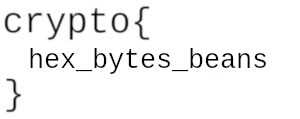

In [13]:
from pathlib import Path

from IPython.display import Image as DisplayImage, display
from pwn import xor

BASE_URL = "https://aes.cryptohack.org/bean_counter"
PNG_HEADER = bytes.fromhex("89504e470d0a1a0a0000000d49484452")

encrypted = bytes.fromhex(requests.get(f"{BASE_URL}/encrypt/").json()["encrypted"])
keystream = strxor(PNG_HEADER, encrypted[:16])
image = xor(encrypted, keystream)  # pwntools' xor repeats the 16-byte keystream

Path("output").mkdir(exist_ok=True)
Path("output/bean_counter.png").write_bytes(image)
display(DisplayImage(data=image))